# 04 — WCS-Aware Visualization and Galaxy Geometry

**Target:** MaNGA plate-IFU `8138-12704`  
**DAPTYPE:** `HYB10-MILESHC-MASTARSSP`

## Goals
- Reopen the MAPS file and load the processed stellar-kinematics arrays from Milestone 3.
- Use the FITS World Coordinate System (WCS) to label maps with sky coordinates.
- Inspect the MaNGA spaxel sky-offset and elliptical-coordinate products.
- Visualize the stellar velocity and corrected dispersion in sky coordinates.
- Create geometry maps and save publication-quality figures.

## Scientific note
The `SPX_SKYCOO` extension contains sky-right offsets in arcseconds relative to the galaxy center (not absolute RA/Dec). The `SPX_ELLCOO` extension contains elliptical radius, radius in units of effective radius, radius in h⁻¹ kpc, and elliptical azimuth. We will use the data products as defined by the MaNGA data model and will not estimate inclination or position angle from a visual guess.

## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 10,
})

## 2. Locate project files

In [2]:
candidate_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path(r"D:\\KS\\manga-stellar-kinematics"),
]
PROJECT_ROOT = next(
    (p.resolve() for p in candidate_roots
     if (p / "data" / "raw").is_dir()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root not found. Set PROJECT_ROOT manually to your project folder."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

maps_matches = list(RAW_DIR.glob(
    "manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits*"
))
npz_path = PROCESSED_DIR / "stellar_kinematics_8138-12704.npz"

if len(maps_matches) != 1:
    raise FileNotFoundError(f"Expected one MAPS file; found: {maps_matches}")
if not npz_path.exists():
    raise FileNotFoundError(
        f"Processed file not found: {npz_path}. "
        "Run Notebook 03 through its save-arrays section first."
    )

MAPS_PATH = maps_matches[0]
print("MAPS:", MAPS_PATH)
print("Processed arrays:", npz_path)

MAPS: D:\KS\manga-stellar-kinematics\data\raw\manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz
Processed arrays: D:\KS\manga-stellar-kinematics\data\processed\stellar_kinematics_8138-12704.npz


## 3. Load processed arrays and MAPS coordinate products

In [3]:
kin = np.load(npz_path)

vel = kin["stellar_velocity_raw"]
vel_valid = kin["stellar_velocity_valid_standard"].astype(bool)
sigma_corr = kin["stellar_sigma_corrected"]
sigma_valid = kin["stellar_sigma_valid_standard"].astype(bool)

maps = fits.open(MAPS_PATH, memmap=True)

for ext in ["SPX_SKYCOO", "SPX_ELLCOO", "SPX_MFLUX", "SPX_SNR", "STELLAR_VEL"]:
    if ext not in {h.name.upper() for h in maps}:
        raise KeyError(f"Required extension {ext} is missing.")

skycoo = np.asarray(maps["SPX_SKYCOO"].data, dtype=float)
ellcoo = np.asarray(maps["SPX_ELLCOO"].data, dtype=float)
mflux = np.asarray(maps["SPX_MFLUX"].data, dtype=float)
snr = np.asarray(maps["SPX_SNR"].data, dtype=float)

print("Velocity map:", vel.shape)
print("SPX_SKYCOO:", skycoo.shape)
print("SPX_ELLCOO:", ellcoo.shape)
print("SPX_MFLUX:", mflux.shape)
print("SPX_SNR:", snr.shape)

if skycoo.shape[0] != 2 or ellcoo.shape[0] != 4:
    raise ValueError("Unexpected coordinate-extension channel layout.")
if skycoo.shape[1:] != vel.shape or ellcoo.shape[1:] != vel.shape:
    raise ValueError("Coordinate-map spatial shape does not match velocity map.")

Velocity map: (72, 72)
SPX_SKYCOO: (2, 72, 72)
SPX_ELLCOO: (4, 72, 72)
SPX_MFLUX: (72, 72)
SPX_SNR: (72, 72)


## 4. Read the coordinate-channel definitions

According to the MaNGA DAP data model:

### `SPX_SKYCOO`
- Channel 0: sky-right offset (arcsec), positive toward increasing RA
- Channel 1: sky-up offset (arcsec), positive toward increasing Dec

### `SPX_ELLCOO`
- Channel 0: elliptical radius (arcsec)
- Channel 1: elliptical radius divided by effective radius, \(R/R_e\)
- Channel 2: elliptical radius in \(h^{-1}\,\mathrm{kpc}\)
- Channel 3: elliptical azimuth (degrees)

These are pipeline-provided coordinates. They are useful for radial and azimuthal analysis, but their interpretation depends on the adopted galaxy geometry in the DAP.

In [4]:
sky_x = skycoo[0]
sky_y = skycoo[1]

ell_radius_arcsec = ellcoo[0]
ell_radius_re = ellcoo[1]
ell_radius_hinv_kpc = ellcoo[2]
ell_azimuth_deg = ellcoo[3]

print("Sky-right offset range [arcsec]:",
      np.nanmin(sky_x), np.nanmax(sky_x))
print("Sky-up offset range [arcsec]:",
      np.nanmin(sky_y), np.nanmax(sky_y))
print("Elliptical R/Re range:",
      np.nanmin(ell_radius_re), np.nanmax(ell_radius_re))
print("Elliptical azimuth range [deg]:",
      np.nanmin(ell_azimuth_deg), np.nanmax(ell_azimuth_deg))

Sky-right offset range [arcsec]: -17.488868713378906 18.014148712158203
Sky-up offset range [arcsec]: -18.002002716064453 17.49880599975586
Elliptical R/Re range: 0.001636298606172204 3.1322615146636963
Elliptical azimuth range [deg]: 0.001439351006411016 359.8417663574219


## 5. Inspect the WCS in the stellar-velocity extension

In [5]:
vel_header = maps["STELLAR_VEL"].header
print("CTYPE1:", vel_header.get("CTYPE1"))
print("CTYPE2:", vel_header.get("CTYPE2"))
print("CRVAL1:", vel_header.get("CRVAL1"))
print("CRVAL2:", vel_header.get("CRVAL2"))
print("CRPIX1:", vel_header.get("CRPIX1"))
print("CRPIX2:", vel_header.get("CRPIX2"))
print("CUNIT1:", vel_header.get("CUNIT1"))
print("CUNIT2:", vel_header.get("CUNIT2"))

wcs_full = WCS(vel_header)
wcs_celestial = wcs_full.celestial
print(wcs_celestial)

CTYPE1: RA---TAN
CTYPE2: DEC--TAN
CRVAL1: 116.65714
CRVAL2: 44.790516
CRPIX1: 37.0
CRPIX2: 37.0
CUNIT1: deg
CUNIT2: deg
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 116.65714 44.790516
CRPIX : 37.0 37.0
PC1_1 PC1_2  : -0.000138889 0.0
PC2_1 PC2_2  : 0.0 0.000138889
CDELT : 1.0 1.0
NAXIS : 72  72


## 6. Plot stellar velocity with celestial WCS axes

This plot uses the celestial WCS attached to the MAPS image extension. The axes should display right ascension and declination rather than pixel indices. If the header has no usable celestial WCS, stop and inspect the printed header instead of silently substituting invented coordinates.

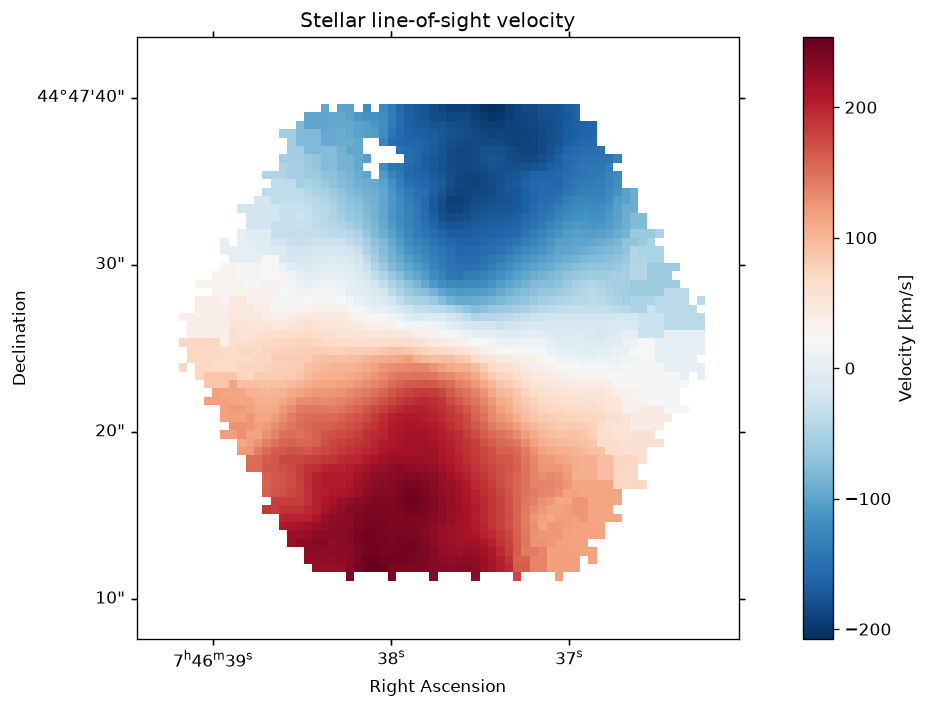

Saved: D:\KS\manga-stellar-kinematics\outputs\figures\stellar_velocity_map_wcs.png


In [6]:
vel_display = np.where(vel_valid, vel, np.nan)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection=wcs_celestial)
im = ax.imshow(vel_display, origin="lower", cmap="RdBu_r")
ax.set_title("Stellar line-of-sight velocity")
ax.set_xlabel("Right Ascension")
ax.set_ylabel("Declination")
ax.coords[0].set_axislabel("Right Ascension")
ax.coords[1].set_axislabel("Declination")
cbar = fig.colorbar(im, ax=ax, pad=0.08)
cbar.set_label(f"Velocity [{vel_header.get('BUNIT', 'unit not recorded')}]")
fig.tight_layout()

wcs_vel_path = FIGURES_DIR / "stellar_velocity_map_wcs.png"
fig.savefig(wcs_vel_path, bbox_inches="tight")
plt.show()
print("Saved:", wcs_vel_path)

## 7. Plot corrected stellar dispersion with celestial WCS axes

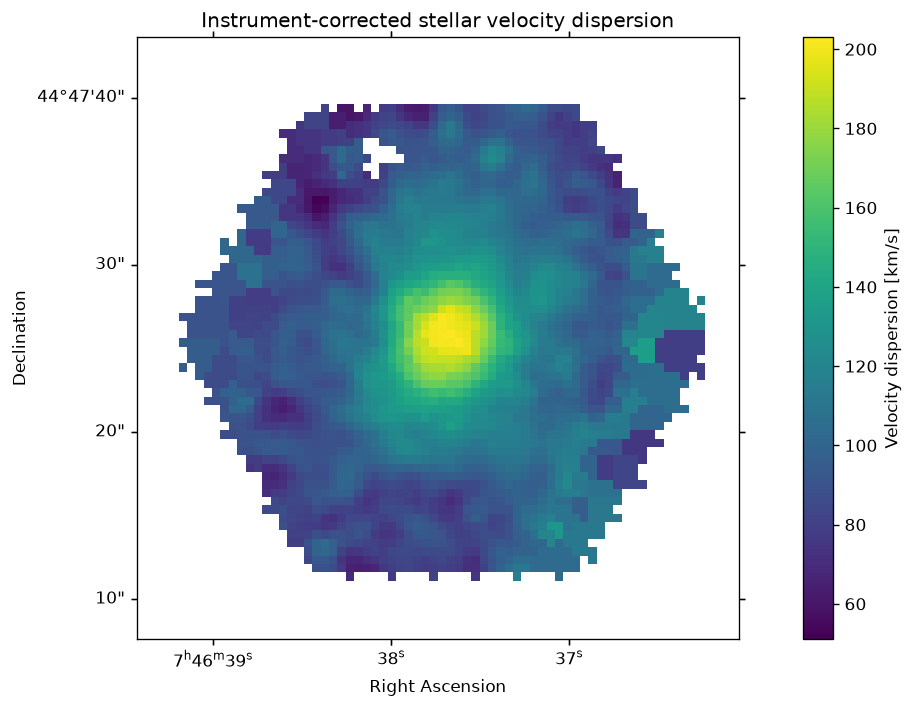

Saved: D:\KS\manga-stellar-kinematics\outputs\figures\stellar_sigma_corrected_map_wcs.png


In [7]:
sigma_display = np.where(sigma_valid, sigma_corr, np.nan)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection=wcs_celestial)
im = ax.imshow(sigma_display, origin="lower", cmap="viridis")
ax.set_title("Instrument-corrected stellar velocity dispersion")
ax.set_xlabel("Right Ascension")
ax.set_ylabel("Declination")
ax.coords[0].set_axislabel("Right Ascension")
ax.coords[1].set_axislabel("Declination")
cbar = fig.colorbar(im, ax=ax, pad=0.08)
cbar.set_label("Velocity dispersion [km/s]")
fig.tight_layout()

wcs_sigma_path = FIGURES_DIR / "stellar_sigma_corrected_map_wcs.png"
fig.savefig(wcs_sigma_path, bbox_inches="tight")
plt.show()
print("Saved:", wcs_sigma_path)

## 8. Plot the spaxel sky-offset coordinate maps

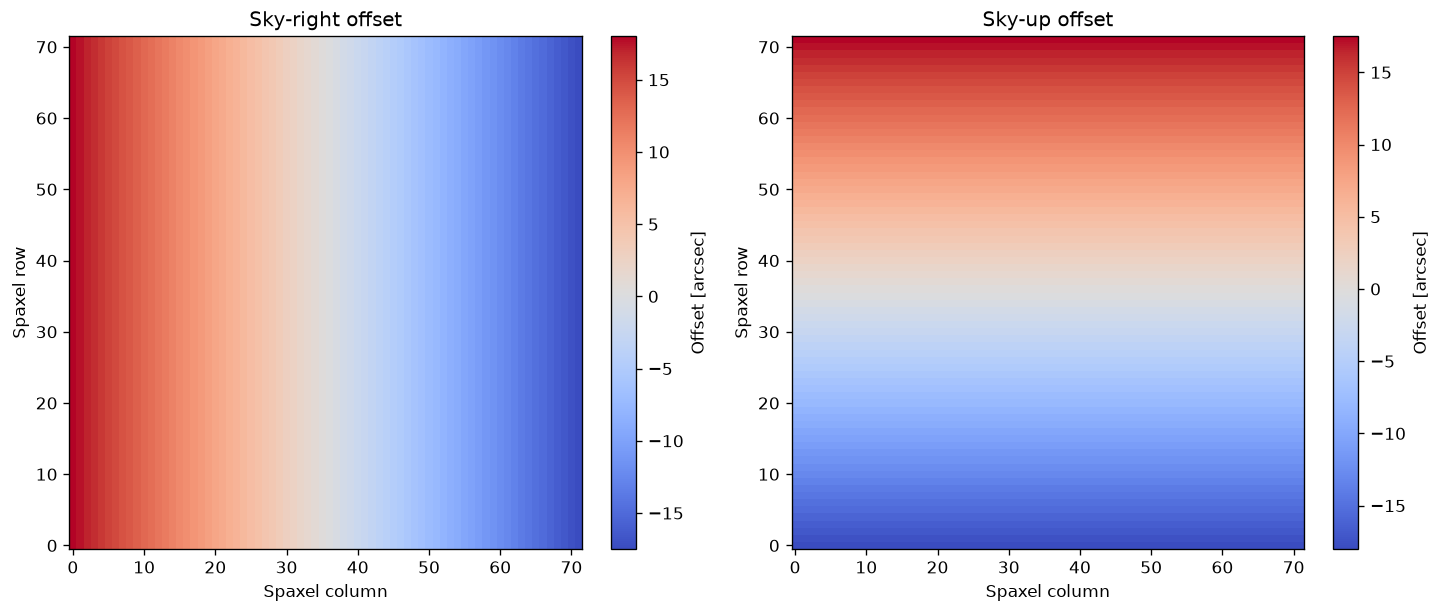

Saved: D:\KS\manga-stellar-kinematics\outputs\figures\spaxel_sky_offsets.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

im0 = axes[0].imshow(sky_x, origin="lower", cmap="coolwarm")
axes[0].set_title("Sky-right offset")
axes[0].set_xlabel("Spaxel column")
axes[0].set_ylabel("Spaxel row")
fig.colorbar(im0, ax=axes[0], label="Offset [arcsec]")

im1 = axes[1].imshow(sky_y, origin="lower", cmap="coolwarm")
axes[1].set_title("Sky-up offset")
axes[1].set_xlabel("Spaxel column")
axes[1].set_ylabel("Spaxel row")
fig.colorbar(im1, ax=axes[1], label="Offset [arcsec]")

sky_offset_path = FIGURES_DIR / "spaxel_sky_offsets.png"
fig.savefig(sky_offset_path, bbox_inches="tight")
plt.show()
print("Saved:", sky_offset_path)

## 9. Plot elliptical radius and azimuth

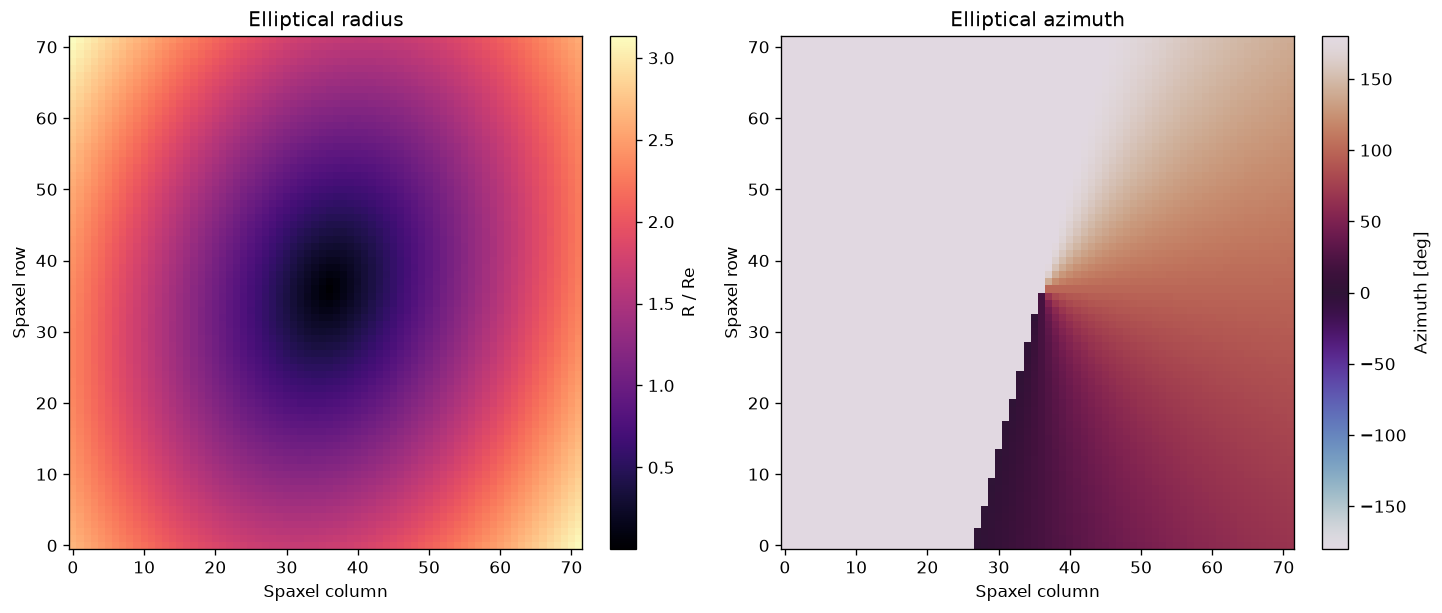

Saved: D:\KS\manga-stellar-kinematics\outputs\figures\elliptical_geometry_maps.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

im0 = axes[0].imshow(ell_radius_re, origin="lower", cmap="magma")
axes[0].set_title("Elliptical radius")
axes[0].set_xlabel("Spaxel column")
axes[0].set_ylabel("Spaxel row")
fig.colorbar(im0, ax=axes[0], label="R / Re")

im1 = axes[1].imshow(ell_azimuth_deg, origin="lower",
                     cmap="twilight", vmin=-180, vmax=180)
axes[1].set_title("Elliptical azimuth")
axes[1].set_xlabel("Spaxel column")
axes[1].set_ylabel("Spaxel row")
fig.colorbar(im1, ax=axes[1], label="Azimuth [deg]")

ell_geometry_path = FIGURES_DIR / "elliptical_geometry_maps.png"
fig.savefig(ell_geometry_path, bbox_inches="tight")
plt.show()
print("Saved:", ell_geometry_path)

## 10. Plot the r-band mean-flux and S/N maps

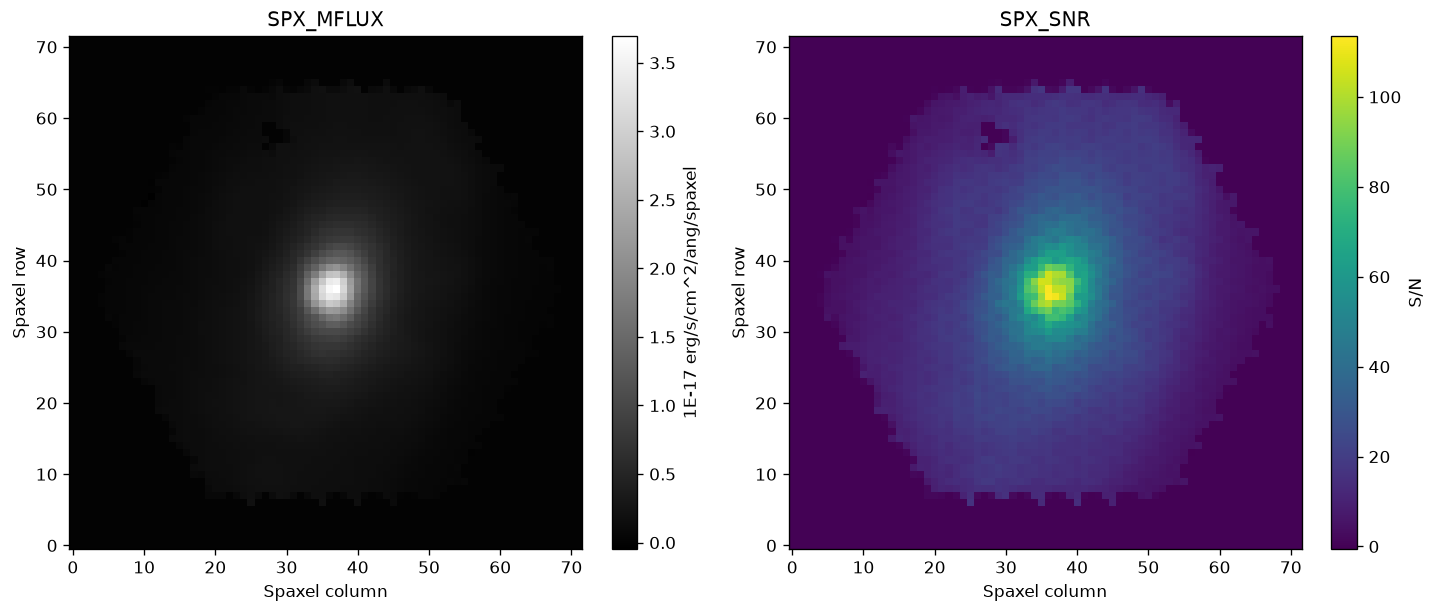

Saved: D:\KS\manga-stellar-kinematics\outputs\figures\manga_flux_snr_context.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

im0 = axes[0].imshow(mflux, origin="lower", cmap="gray")
axes[0].set_title("SPX_MFLUX")
axes[0].set_xlabel("Spaxel column")
axes[0].set_ylabel("Spaxel row")
fig.colorbar(im0, ax=axes[0], label=maps["SPX_MFLUX"].header.get("BUNIT", "Flux"))

im1 = axes[1].imshow(snr, origin="lower", cmap="viridis")
axes[1].set_title("SPX_SNR")
axes[1].set_xlabel("Spaxel column")
axes[1].set_ylabel("Spaxel row")
fig.colorbar(im1, ax=axes[1], label="S/N")

context_path = FIGURES_DIR / "manga_flux_snr_context.png"
fig.savefig(context_path, bbox_inches="tight")
plt.show()
print("Saved:", context_path)

## 11. Overlay a zero-offset reference on the velocity map

Nearest zero-offset spaxel (row, col): (np.int64(36), np.int64(36))
Its sky offset [arcsec]: 0.012618524953722954 -0.0012085200287401676
Offset distance [arcsec]: 0.012676264933630688


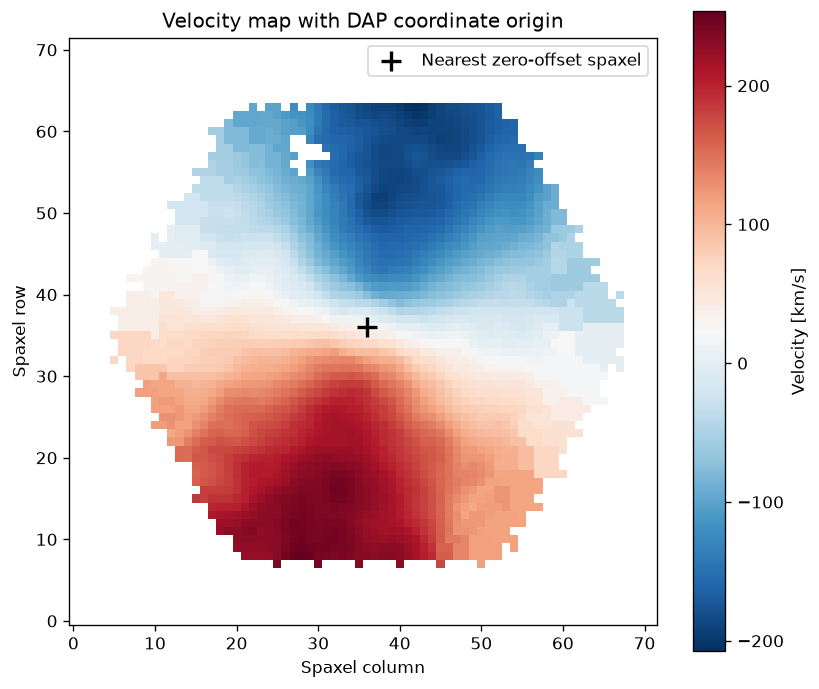

In [11]:
# The SPX_SKYCOO origin is defined relative to the galaxy center.
# Locate the spaxel whose sky offset is closest to (0, 0) arcsec.
offset_radius = np.hypot(sky_x, sky_y)
center_index = np.unravel_index(np.nanargmin(offset_radius), offset_radius.shape)
cy, cx = center_index

print("Nearest zero-offset spaxel (row, col):", center_index)
print("Its sky offset [arcsec]:", sky_x[cy, cx], sky_y[cy, cx])
print("Offset distance [arcsec]:", offset_radius[cy, cx])

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(vel_display, origin="lower", cmap="RdBu_r")
ax.scatter(cx, cy, marker="+", s=150, linewidths=2,
           color="black", label="Nearest zero-offset spaxel")
ax.set_title("Velocity map with DAP coordinate origin")
ax.set_xlabel("Spaxel column")
ax.set_ylabel("Spaxel row")
ax.legend()
fig.colorbar(im, ax=ax, label=f"Velocity [{vel_header.get('BUNIT', 'unit')}]")
fig.tight_layout()
plt.show()

## 12. Save geometry arrays for later quantitative analysis

In [12]:
geometry_path = PROCESSED_DIR / "manga_geometry_8138-12704.npz"

np.savez_compressed(
    geometry_path,
    sky_right_offset_arcsec=sky_x,
    sky_up_offset_arcsec=sky_y,
    elliptical_radius_arcsec=ell_radius_arcsec,
    elliptical_radius_re=ell_radius_re,
    elliptical_radius_hinv_kpc=ell_radius_hinv_kpc,
    elliptical_azimuth_deg=ell_azimuth_deg,
    spx_mflux=mflux,
    spx_snr=snr,
    nearest_zero_offset_spaxel=np.asarray(center_index),
)
print("Saved:", geometry_path)

Saved: D:\KS\manga-stellar-kinematics\data\processed\manga_geometry_8138-12704.npz


## 13. Close the FITS file

In [13]:
maps.close()
kin.close()
print("MAPS FITS and processed NPZ files closed.")

MAPS FITS and processed NPZ files closed.


## 14. Milestone 4 checklist

- [ ] Celestial WCS header inspected.
- [ ] Velocity map plotted with RA/Dec axes.
- [ ] Corrected dispersion map plotted with RA/Dec axes.
- [ ] `SPX_SKYCOO` offsets inspected.
- [ ] `SPX_ELLCOO` radius and azimuth inspected.
- [ ] Flux and S/N context maps inspected.
- [ ] Geometry arrays saved.

### Interpretation cautions
- `SPX_SKYCOO` are offsets in arcseconds, not absolute sky coordinates.
- `SPX_ELLCOO` are pipeline-derived elliptical coordinates; they are not independent measurements of a new position angle or inclination.
- Do not infer a kinematic position angle from a single image by eye. We will estimate geometry quantitatively and compare it with catalog/pipeline metadata in the next analysis.
- The MAPS WCS maps pixel positions to the sky; it does not by itself deproject the galaxy into its disk plane.

**Next milestone:** quantitative velocity-field analysis — estimate systemic velocity, rotation axis/kinematic position angle, radial profiles, and velocity-dispersion statistics with uncertainty and mask handling.